# Statistical Time Series Analysis & Diagnostics

Run ACF/PACF and stationarity diagnostics per restaurant. Annual seasonality is not identifiable with confidence from this history.


Chimi & Churri training-only interpolated dates: [Timestamp('2016-04-05 00:00:00'), Timestamp('2016-09-17 00:00:00')]
Chimi & Churri ADF p-value: 0.000283865203156855 KPSS p-value: 0.09122250502195944


/tmp/ipykernel_216641/1082319390.py:28: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  print(target, "ADF p-value:", adfuller(y)[1], "KPSS p-value:", kpss(y, regression="c", nlags="auto")[1])
/tmp/ipykernel_216641/1082319390.py:28: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  print(target, "ADF p-value:", adfuller(y)[1], "KPSS p-valu

/tmp/ipykernel_216641/1082319390.py:34: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  classical = seasonal_decompose(y, model="additive", period=7, extrapolate_trend="freq")
/tmp/ipykernel_216641/1082319390.py:28: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  print(target, "ADF p-value:", adfuller(y)[1], "KPSS p-value:", kpss(y, regression="c", nlags="auto")[1])
/tmp/ipykernel_216641/1082319390.py:28: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  print(target, "ADF p-value:", a

Assa Frão training-only interpolated dates: [Timestamp('2016-11-24 00:00:00')]
Assa Frão ADF p-value: 0.0002670919456776823 KPSS p-value: 0.01


/tmp/ipykernel_216641/1082319390.py:34: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  classical = seasonal_decompose(y, model="additive", period=7, extrapolate_trend="freq")


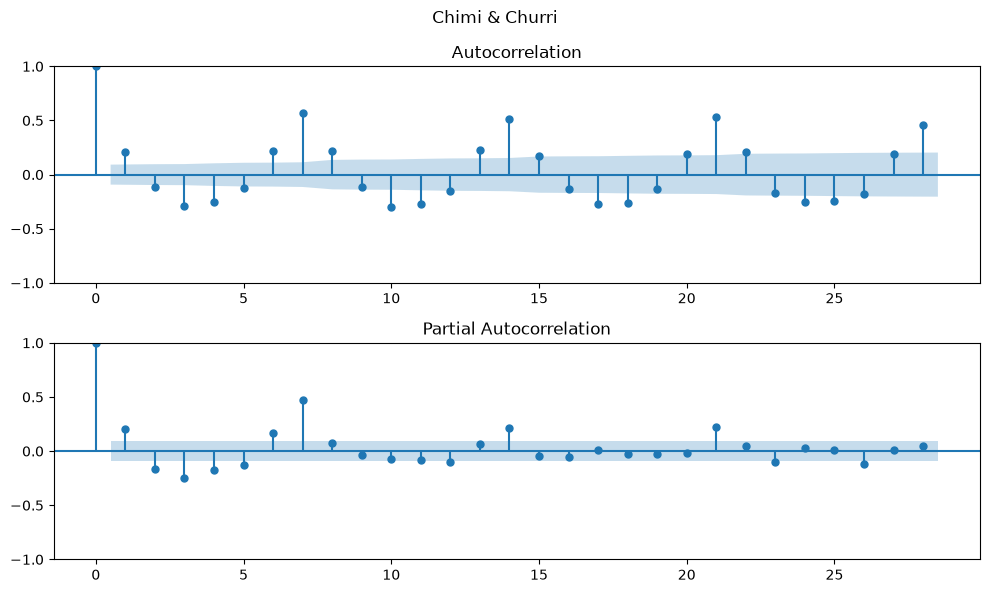

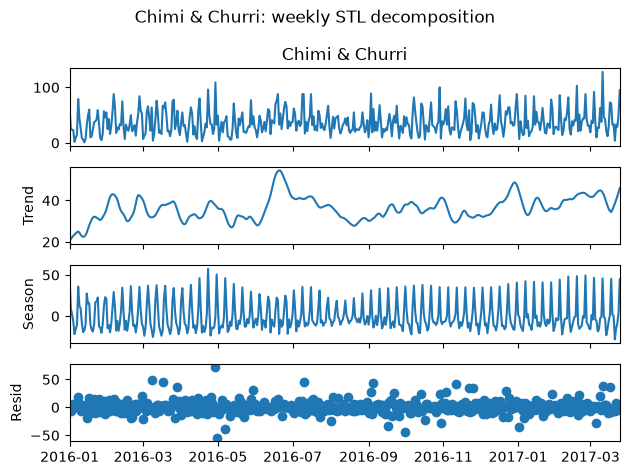

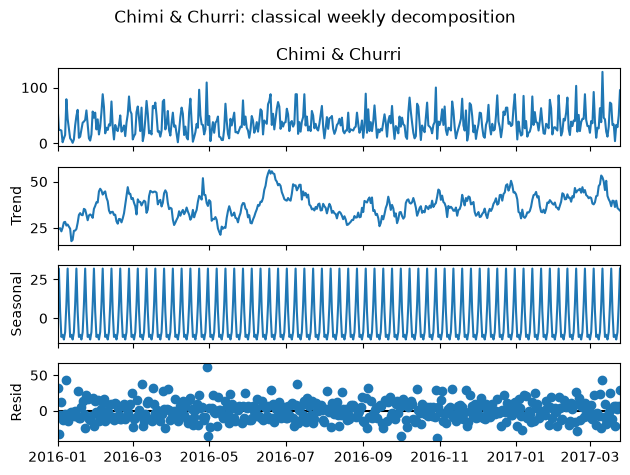

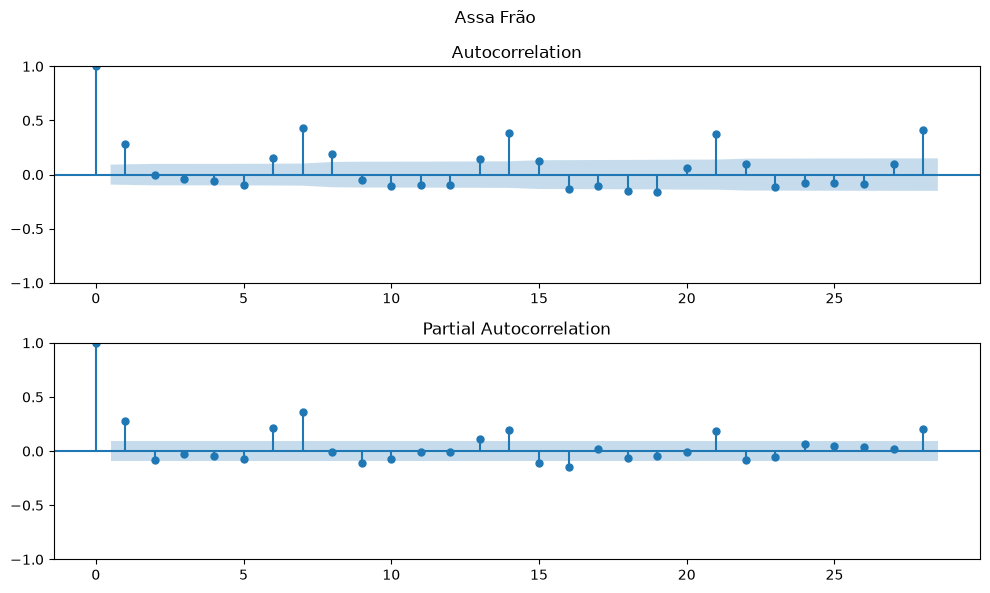

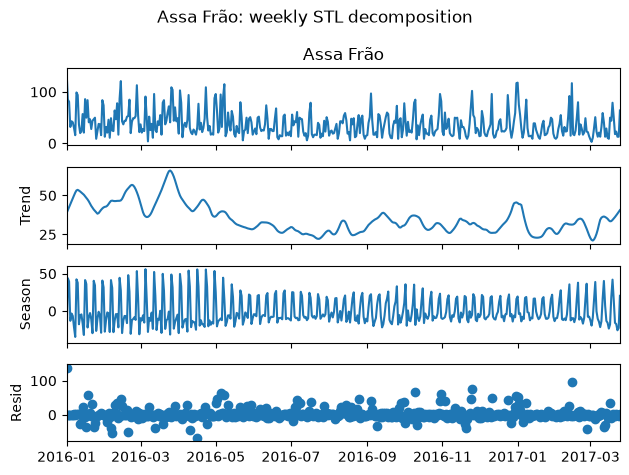

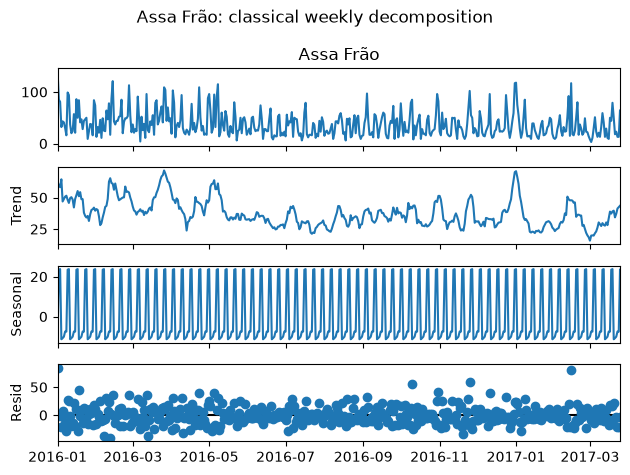

In [1]:
# PROJECT_ROOT_BOOTSTRAP: support kernels started from the repository root or notebooks/.
from pathlib import Path
import os
import sys

ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "src").is_dir():
    raise FileNotFoundError("Could not locate the project root containing src/.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.seasonal import STL, seasonal_decompose
from src.data import load_demand, TARGETS
from src.evaluation import chronological_holdout

demand = load_demand("data/raw/clientes_restaurantes.csv")
for target in TARGETS:
    train, _ = chronological_holdout(demand[[target]], 28)
    missing_dates = train.index[train[target].isna()]
    print(target, "training-only interpolated dates:", missing_dates.tolist())
    y = train[target].interpolate(limit_area="inside").dropna()
    print(target, "ADF p-value:", adfuller(y)[1], "KPSS p-value:", kpss(y, regression="c", nlags="auto")[1])
    fig, axes = plt.subplots(2, 1, figsize=(10, 6))
    plot_acf(y, lags=28, ax=axes[0]); plot_pacf(y, lags=28, ax=axes[1])
    fig.suptitle(target); plt.tight_layout()
    stl = STL(y, period=7, robust=True).fit()
    stl.plot(); plt.suptitle(f"{target}: weekly STL decomposition"); plt.tight_layout()
    classical = seasonal_decompose(y, model="additive", period=7, extrapolate_trend="freq")
    classical.plot(); plt.suptitle(f"{target}: classical weekly decomposition"); plt.tight_layout()